## 0. Import

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, accuracy_score

import tensorflow as tf
from keras.models import Model
from keras.layers import (Input, Conv2D, MaxPooling2D, Permute, Reshape, Dense,
                        Embedding, GRU, Bidirectional, Activation, AdditiveAttention, Concatenate,
                        BatchNormalization)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

## 1. Read dataset

In [20]:
images = np.load("../datasets/images.npy", mmap_mode="r")
labels = np.load("../datasets/labels.npy")

max_len = max(len(str(label)) for label in labels)

print("Number of images:", len(images))
print("Image shape:", images.shape)
print("Maximum label length:", max_len)

Number of images: 60000
Image shape: (60000, 28, 224, 1)
Maximum label length: 8


In [21]:
IMG_SHAPE = (28, 224, 1)
MAX_LABEL_LENGTH = 8  
MAX_OUTPUT_LENGTH = MAX_LABEL_LENGTH + 1

PAD_TOKEN = 10
START_TOKEN = 11
END_TOKEN = 12

VOCAB_SIZE = 13

VERSION = "v3"

## 2. Preprocessing

In [22]:
# Chuyển label từ chuỗi thành danh sách các chữ số
def decode_labels(labels):
    seq = np.full((len(labels), MAX_OUTPUT_LENGTH + 1), PAD_TOKEN, dtype=np.int64)
    for i, label in enumerate(labels):
        digits = [int(d) for d in str(label)]
        seq[i, 0] = START_TOKEN
        seq[i, 1 : len(digits) + 1] = digits
        seq[i, len(digits) + 1] = END_TOKEN

    dec_in = seq[:, :-1]
    dec_out = seq[:, 1:]
    return dec_in, dec_out

## 3. Data Split

Chia train/val/test = 70/15/15

In [23]:
idx = np.arange(len(images))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=42)

X_train, X_val, X_test = images[idx_train], images[idx_val], images[idx_test]
y_train, y_val, y_test = labels[idx_train], labels[idx_val], labels[idx_test]

Din_train, Dout_train = decode_labels(y_train)
Din_val, Dout_val = decode_labels(y_val)

print('Train:', X_train.shape)
print('Validation:', X_val.shape)
print('Test:', X_test.shape)

Train: (42000, 28, 224, 1)
Validation: (9000, 28, 224, 1)
Test: (9000, 28, 224, 1)


In [28]:
print("Maximum digit length:", MAX_LABEL_LENGTH)
print("Target length:", MAX_OUTPUT_LENGTH)

print("\nExample labels:")
for i in range(3):
    print("Original:", y_train[i])
    print("Decoder input:", Din_train[i])
    print("Decoder target:", Dout_train[i])
    print()

Maximum digit length: 8
Target length: 9

Example labels:
Original: 6057
Decoder input: [11  6  0  5  7 12 10 10 10]
Decoder target: [ 6  0  5  7 12 10 10 10 10]

Original: 41297766
Decoder input: [11  4  1  2  9  7  7  6  6]
Decoder target: [ 4  1  2  9  7  7  6  6 12]

Original: 1645295
Decoder input: [11  1  6  4  5  2  9  5 12]
Decoder target: [ 1  6  4  5  2  9  5 12 10]



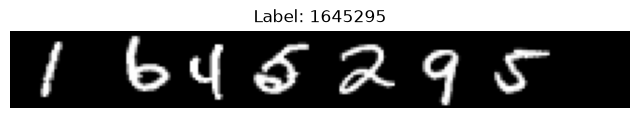

In [29]:
plt.figure(figsize=(8, 2))
plt.imshow(X_train[2].squeeze(), cmap='gray')
plt.title(f"Label: {y_train[2]}")
plt.axis('off')
plt.show()

## 4. Train model

In [8]:
# Encoder
img_input = Input(shape=IMG_SHAPE, name='encoder_input')
x = Conv2D(32, (3, 3), padding='same', use_bias=False)(img_input)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(64, (3, 3), padding='same', use_bias=False)(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)                             # (7, 56, 64)

x = Permute((2, 1, 3))(x)                               # (56, 7, 64)
x = Reshape((56, 7 * 64))(x)                            # (56 timesteps, 448 features)
enc_out, f_h, b_h = Bidirectional(GRU(64, return_sequences=True, return_state=True))(x)
enc_state = Concatenate()([f_h, b_h])

# Decoder
dec_input = Input(shape=(MAX_OUTPUT_LENGTH,), name='decoder_input')
dec_emb = Embedding(VOCAB_SIZE, 128)(dec_input)
dec_out = GRU(128, return_sequences=True)(dec_emb, initial_state=enc_state)

# Attention mechanism
context  = AdditiveAttention()([dec_out, enc_out])
combined = Concatenate()([context, dec_out])

# Output layer
outputs = Dense(VOCAB_SIZE, activation='softmax')(combined)



I0000 00:00:1795424882.706804  127326 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 11897 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Ti SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


In [9]:
model = Model(inputs=[img_input, dec_input], outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', weighted_metrics=['sparse_categorical_accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 28, 224,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 224,   │        288 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 28, 224,   │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 28, 224,   │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 14, 112,   │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 14, 112,   │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 112,   │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 14, 112,   │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 7, 56, 64) │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 56, 7, 64) │          0 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 56, 448)   │          0 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ [(None, 56, 128), │    197,376 │ reshape[0][0]     │
│ (Bidirectional)     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 9, 128)    │      1,664 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ bidirectional[0]… │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 9, 128)    │     99,072 │ embedding[0][0],  │
│                     │                   │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ (None, 9, 128)    │        128 │ gru_1[0][0],      │
│ (AdditiveAttention) │                   │            │ bidirectional[0]

 Total params: 320,685 (1.22 MB)

 Trainable params: 320,493 (1.22 MB)

 Non-trainable params: 192 (768.00 B)

In [10]:
# Mask những vị trí PAD
train_mask = (Dout_train != PAD_TOKEN).astype('float64')
val_mask = (Dout_val != PAD_TOKEN).astype('float64')

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

# Training
history = model.fit([X_train, Din_train], Dout_train, 
                    sample_weight=train_mask, 
                    epochs=50, 
                    batch_size=64, 
                    verbose=1, 
                    validation_data=([X_val, Din_val], Dout_val, val_mask), 
                    callbacks=[early_stop, reduce_lr])

Epoch 1/50


I0000 00:00:1795424885.017291  127482 cuda_dnn.cc:461] Loaded cuDNN version 92801


657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - loss: 0.6272 - sparse_categorical_accuracy: 0.7341 - val_loss: 0.2012 - val_sparse_categorical_accuracy: 0.9241 - learning_rate: 0.0010
Epoch 2/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - loss: 0.0621 - sparse_categorical_accuracy: 0.9795 - val_loss: 0.0352 - val_sparse_categorical_accuracy: 0.9883 - learning_rate: 0.0010
Epoch 3/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - loss: 0.0240 - sparse_categorical_accuracy: 0.9919 - val_loss: 0.0251 - val_sparse_categorical_accuracy: 0.9906 - learning_rate: 0.0010
Epoch 4/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - loss: 0.0204 - sparse_categorical_accuracy: 0.9926 - val_loss: 0.0201 - val_sparse_categorical_accuracy: 0.9924 - learning_rate: 0.0010
Epoch 5/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - loss: 0.0104 - sparse_categorical_accuracy: 0.9962 - val_loss: 0.0221 - val_sparse_categorical_accuracy: 0.9911 - learning_rate: 0.0010
Epoch 6/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/st

## 5. Prediction

In [11]:
# khi dự đoán không có nhãn thật nên phải sinh từng chữ số một,
# chữ số vừa sinh ra được đưa vào làm input cho bước kế tiếp

# Khởi tạo Test decoder input với toàn bộ là PAD_TOKEN, riêng vị trí đầu tiên là START_TOKEN
n_samples = len(X_test)
test_dec_in = np.full((n_samples, MAX_OUTPUT_LENGTH), PAD_TOKEN, dtype=np.int64)
test_dec_in[:, 0] = START_TOKEN

for t in range(MAX_OUTPUT_LENGTH):
    preds = model.predict([X_test, test_dec_in], batch_size=256, verbose=0)

    # Chỉ cho phép dự đoán digit hoặc END
    logits = preds[:, t, :].copy()
    logits[:, PAD_TOKEN] = -1
    logits[:, START_TOKEN] = -1
    next_token = np.argmax(logits, axis=-1)

    if t + 1 < MAX_OUTPUT_LENGTH:
        test_dec_in[:, t + 1] = next_token

outputs = []
for seq in test_dec_in[:, 1:]:
    # Lấy các token từ vị trí 1 đến khi gặp END_TOKEN hoặc hết độ dài
    output = []
    for token in seq:
        if token >= 10:
            break
        output.append(str(token))
    outputs.append(float(''.join(output)) if output else 0.0)

y_pred = np.array(outputs, dtype=np.float64)

## 6. Evaluation

In [12]:
y_true_num = np.array(y_test, dtype=np.float64)
y_pred_num = np.array(y_pred, dtype=np.float64)

mae     = mean_absolute_error(y_true_num, y_pred_num)
rmse    = np.sqrt(mean_squared_error(y_true_num, y_pred_num))
r2      = r2_score(y_true_num, y_pred_num)
nse_denom   = np.sum((y_true_num - np.mean(y_true_num)) ** 2)
nse     = 1.0 - np.sum((y_true_num - y_pred_num) ** 2) / nse_denom if nse_denom else np.nan
acc     = accuracy_score(y_true_num, y_pred_num)

print(f"Sequence Accuracy: {acc:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2:   {r2:.4f}")
print(f"NSE:  {nse:.4f}")

Sequence Accuracy: 0.9911
MAE:  10355.1921
RMSE: 473316.7250
R2:   0.9994
NSE:  0.9994


### Save Result

In [13]:
output_path = "../output/DaiModel/"  
csv_path = output_path + "dai_model_results.csv"   
model_path = output_path + f"dai_model_{VERSION}.keras"   

import os
os.makedirs(output_path, exist_ok=True)

model.save(model_path)  

results = {
    "Model": f"Dai Model {VERSION}",     
    "Version": VERSION,
    "Sequence_Accuracy": acc,
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2,
    "NSE": nse
}

results_df = pd.DataFrame([results])

if os.path.exists(csv_path):
    # Đồng bộ tên cột kết quả cũ của Đại với cấu trúc Base_Model.
    previous_results = pd.read_csv(csv_path).rename(columns={
        "model": "Model",
        "Accuracy": "Sequence_Accuracy"
    })
    if "Version" not in previous_results.columns:
        previous_results["Version"] = previous_results["Model"].str.extract(
            r"(v[0-9]+)$", expand=False
        )
    previous_results = previous_results.reindex(columns=results_df.columns)
    results_df = pd.concat([previous_results, results_df], ignore_index=True)
results_df.to_csv(csv_path, index=False)

print(f"Model saved: {model_path}")
print(f"Results saved: {csv_path}")

Model saved: ../output/DaiModel/dai_model_v3.keras
Results saved: ../output/DaiModel/dai_model_results.csv
